In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/processed/feature_engineered_sales_data.csv")
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Month,Day,DayOfWeek,Quarter,Price_Difference,Price_Ratio,Price_Difference_Percent,Effective_Price,Stock_Status,Inventory_to_Order_Ratio
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,1,1,5,1,-13.01,0.848244,-15.175551,69.084,In_Stock,0.770751
1,2022-01-01,S004,P0013,Groceries,West,136,104,385,20.24,10,...,1,1,5,1,1.34,1.070899,7.089947,18.216,In_Stock,0.352332
2,2022-01-01,S004,P0012,Electronics,West,111,111,113,118.15,0,...,1,1,5,1,-15.31,0.885284,-11.471602,118.150,In_Stock,0.973684
3,2022-01-01,S004,P0011,Clothing,West,195,60,293,52.89,0,...,1,1,5,1,-9.40,0.849093,-15.090705,52.890,In_Stock,0.663265
4,2022-01-01,S004,P0010,Groceries,West,223,120,597,30.02,0,...,1,1,5,1,0.87,1.029846,2.984563,30.020,In_Stock,0.372910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S002,P0008,Groceries,South,85,81,94,26.98,0,...,1,30,1,1,2.33,1.094523,9.452333,26.980,In_Stock,0.894737
75996,2024-01-30,S002,P0007,Toys,South,414,126,0,26.84,10,...,1,30,1,1,-2.71,0.908291,-9.170897,24.156,In_Stock,414.000000
75997,2024-01-30,S002,P0006,Clothing,South,98,96,117,63.58,10,...,1,30,1,1,-12.64,0.834164,-16.583574,57.222,In_Stock,0.830508
75998,2024-01-30,S002,P0016,Clothing,South,88,78,0,91.50,5,...,1,30,1,1,5.76,1.067180,6.717985,86.925,In_Stock,88.000000


In [3]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Month,Day,DayOfWeek,Quarter,Price_Difference,Price_Ratio,Price_Difference_Percent,Effective_Price,Stock_Status,Inventory_to_Order_Ratio
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,1,1,5,1,-13.01,0.848244,-15.175551,69.084,In_Stock,0.770751
1,2022-01-01,S004,P0013,Groceries,West,136,104,385,20.24,10,...,1,1,5,1,1.34,1.070899,7.089947,18.216,In_Stock,0.352332
2,2022-01-01,S004,P0012,Electronics,West,111,111,113,118.15,0,...,1,1,5,1,-15.31,0.885284,-11.471602,118.150,In_Stock,0.973684
3,2022-01-01,S004,P0011,Clothing,West,195,60,293,52.89,0,...,1,1,5,1,-9.40,0.849093,-15.090705,52.890,In_Stock,0.663265
4,2022-01-01,S004,P0010,Groceries,West,223,120,597,30.02,0,...,1,1,5,1,0.87,1.029846,2.984563,30.020,In_Stock,0.372910


In [4]:
df.shape

(76000, 27)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      76000 non-null  str    
 1   Store ID                  76000 non-null  str    
 2   Product ID                76000 non-null  str    
 3   Category                  76000 non-null  str    
 4   Region                    76000 non-null  str    
 5   Inventory Level           76000 non-null  int64  
 6   Units Sold                76000 non-null  int64  
 7   Units Ordered             76000 non-null  int64  
 8   Price                     76000 non-null  float64
 9   Discount                  76000 non-null  int64  
 10  Weather Condition         76000 non-null  str    
 11  Promotion                 76000 non-null  int64  
 12  Competitor Pricing        76000 non-null  float64
 13  Seasonality               76000 non-null  str    
 14  Epidemic         

In [6]:
target = "Demand"

In [7]:
df[target].describe()

count    76000.000000
mean       104.317158
std         46.964801
min          4.000000
25%         71.000000
50%        100.000000
75%        133.000000
max        430.000000
Name: Demand, dtype: float64

In [8]:
y = df["Demand"]

In [9]:
drop_columns = ["Demand","Date"]
X = df.drop(columns=drop_columns)

In [10]:
X.head()

,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,...,Month,Day,DayOfWeek,Quarter,Price_Difference,Price_Ratio,Price_Difference_Percent,Effective_Price,Stock_Status,Inventory_to_Order_Ratio
0,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,...,1,1,5,1,-13.01,0.848244,-15.175551,69.084,In_Stock,0.770751
1,S004,P0013,Groceries,West,136,104,385,20.24,10,Snowy,...,1,1,5,1,1.34,1.070899,7.089947,18.216,In_Stock,0.352332
2,S004,P0012,Electronics,West,111,111,113,118.15,0,Snowy,...,1,1,5,1,-15.31,0.885284,-11.471602,118.150,In_Stock,0.973684
3,S004,P0011,Clothing,West,195,60,293,52.89,0,Snowy,...,1,1,5,1,-9.40,0.849093,-15.090705,52.890,In_Stock,0.663265
4,S004,P0010,Groceries,West,223,120,597,30.02,0,Snowy,...,1,1,5,1,0.87,1.029846,2.984563,30.020,In_Stock,0.372910


In [11]:
X.columns.tolist()

['Store ID',
 'Product ID',
 'Category',
 'Region',
 'Inventory Level',
 'Units Sold',
 'Units Ordered',
 'Price',
 'Discount',
 'Weather Condition',
 'Promotion',
 'Competitor Pricing',
 'Seasonality',
 'Epidemic',
 'Year',
 'Month',
 'Day',
 'DayOfWeek',
 'Quarter',
 'Price_Difference',
 'Price_Ratio',
 'Price_Difference_Percent',
 'Effective_Price',
 'Stock_Status',
 'Inventory_to_Order_Ratio']

In [12]:
X.shape

(76000, 25)

In [13]:
X = X.drop(
    columns=["Store ID", "Product ID"],
    errors="ignore"
)

In [14]:
numeric_features = X.select_dtypes(
    include=np.number
).columns

numeric_features

Index(['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Promotion', 'Competitor Pricing', 'Epidemic', 'Year', 'Month', 'Day',
       'DayOfWeek', 'Quarter', 'Price_Difference', 'Price_Ratio',
       'Price_Difference_Percent', 'Effective_Price',
       'Inventory_to_Order_Ratio'],
      dtype='str')

In [15]:
correlation_df = df.select_dtypes(
    include=np.number
).corr()["Demand"].sort_values(
    ascending=False
)

correlation_df

Demand                      1.000000
Units Sold                  0.833421
Units Ordered               0.511963
Promotion                   0.282537
Discount                    0.224723
Inventory Level             0.126618
Month                       0.042436
Quarter                     0.018874
DayOfWeek                   0.006958
Price_Difference            0.002196
Price_Ratio                 0.001611
Price_Difference_Percent    0.001611
Day                        -0.018369
Competitor Pricing         -0.023036
Price                      -0.023461
Year                       -0.036278
Effective_Price            -0.054218
Inventory_to_Order_Ratio   -0.095776
Epidemic                   -0.363661
Name: Demand, dtype: float64

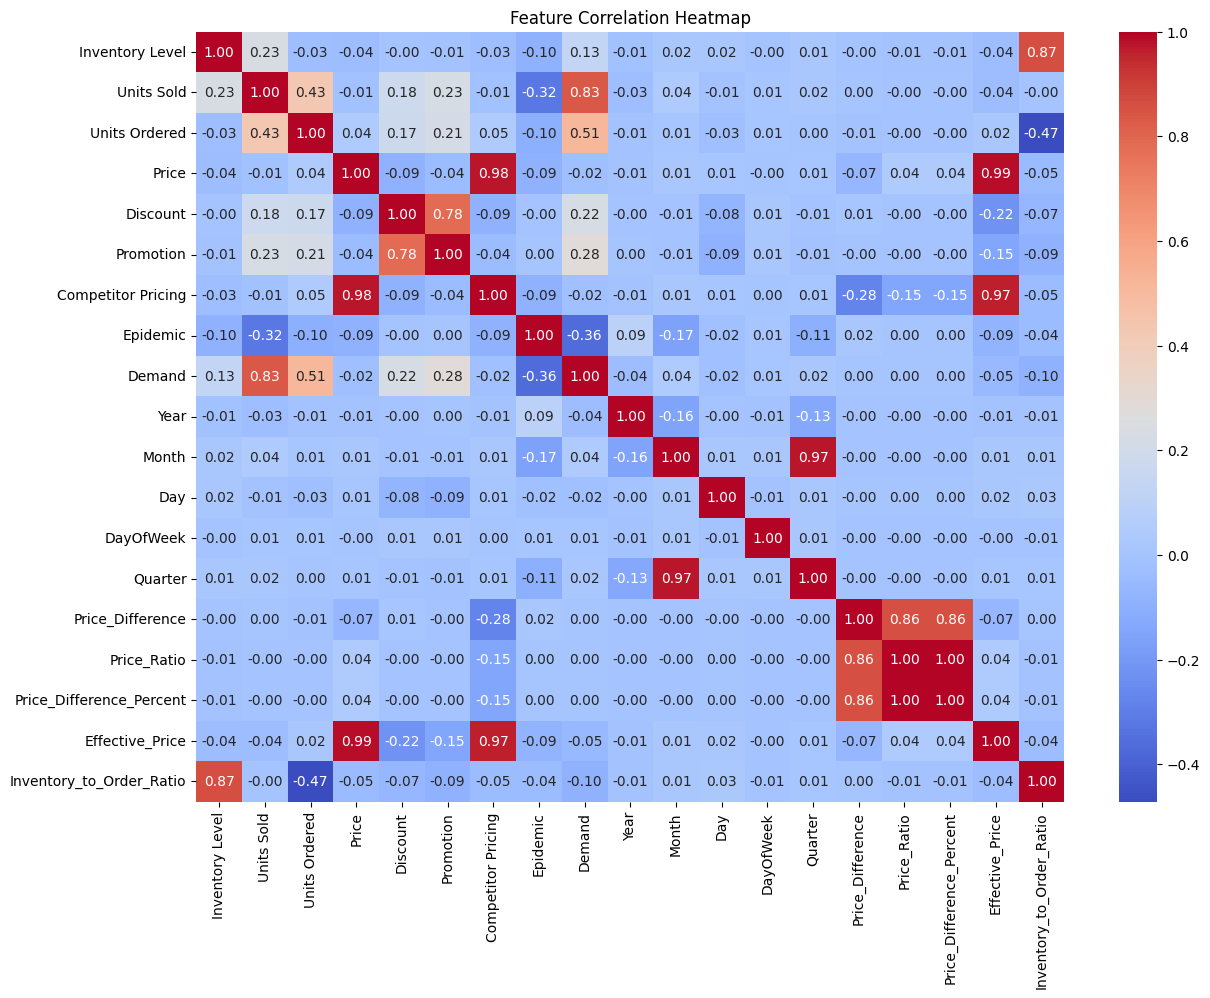

In [16]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [17]:
corr_matrix = X.select_dtypes(
    include=np.number
).corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.90)
]

high_corr_features

['Competitor Pricing',
 'Quarter',
 'Price_Difference_Percent',
 'Effective_Price']

In [18]:
corr_pairs = (
    X.select_dtypes(include=np.number)
    .corr()
    .unstack()
)

corr_pairs = corr_pairs[
    (corr_pairs.abs() > 0.90) &
    (corr_pairs.abs() < 1.00)
].sort_values(ascending=False)

corr_pairs

Price_Ratio               Price_Difference_Percent    1.000000
Price_Difference_Percent  Price_Ratio                 1.000000
Effective_Price           Price                       0.988388
Price                     Effective_Price             0.988388
                          Competitor Pricing          0.976648
Competitor Pricing        Price                       0.976648
Month                     Quarter                     0.972589
Quarter                   Month                       0.972589
Competitor Pricing        Effective_Price             0.965287
Effective_Price           Competitor Pricing          0.965287
dtype: float64

In [19]:
X = X.drop(
    columns=["Price_Ratio", "Effective_Price", "Quarter"],
    errors="ignore"
)

In [20]:
X.columns.tolist()

['Category',
 'Region',
 'Inventory Level',
 'Units Sold',
 'Units Ordered',
 'Price',
 'Discount',
 'Weather Condition',
 'Promotion',
 'Competitor Pricing',
 'Seasonality',
 'Epidemic',
 'Year',
 'Month',
 'Day',
 'DayOfWeek',
 'Price_Difference',
 'Price_Difference_Percent',
 'Stock_Status',
 'Inventory_to_Order_Ratio']

In [21]:
categorical_features = X.select_dtypes(
    include=["object","string"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Category', 'Region', 'Weather Condition', 'Seasonality', 'Stock_Status']

Numerical features:
['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Epidemic', 'Year', 'Month', 'Day', 'DayOfWeek', 'Price_Difference', 'Price_Difference_Percent', 'Inventory_to_Order_Ratio']


In [22]:
X.isnull().sum()

Category                    0
Region                      0
Inventory Level             0
Units Sold                  0
Units Ordered               0
Price                       0
Discount                    0
Weather Condition           0
Promotion                   0
Competitor Pricing          0
Seasonality                 0
Epidemic                    0
Year                        0
Month                       0
Day                         0
DayOfWeek                   0
Price_Difference            0
Price_Difference_Percent    0
Stock_Status                0
Inventory_to_Order_Ratio    0
dtype: int64

In [23]:
y.isnull().sum()

np.int64(0)

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [25]:
X_transformed = preprocessor.fit_transform(X)

X_transformed.shape

(76000, 34)

In [26]:
feature_names = preprocessor.get_feature_names_out()

feature_names

array(['categorical__Category_Clothing',
       'categorical__Category_Electronics',
       'categorical__Category_Furniture',
       'categorical__Category_Groceries', 'categorical__Category_Toys',
       'categorical__Region_East', 'categorical__Region_North',
       'categorical__Region_South', 'categorical__Region_West',
       'categorical__Weather Condition_Cloudy',
       'categorical__Weather Condition_Rainy',
       'categorical__Weather Condition_Snowy',
       'categorical__Weather Condition_Sunny',
       'categorical__Seasonality_Autumn',
       'categorical__Seasonality_Spring',
       'categorical__Seasonality_Summer',
       'categorical__Seasonality_Winter',
       'categorical__Stock_Status_In_Stock',
       'categorical__Stock_Status_Out_of_Stock',
       'numerical__Inventory Level', 'numerical__Units Sold',
       'numerical__Units Ordered', 'numerical__Price',
       'numerical__Discount', 'numerical__Promotion',
       'numerical__Competitor Pricing', 'numerical_

In [27]:
X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X.index
)

In [28]:
X_transformed_df.head()

,categorical__Category_Clothing,categorical__Category_Electronics,categorical__Category_Furniture,categorical__Category_Groceries,categorical__Category_Toys,categorical__Region_East,categorical__Region_North,categorical__Region_South,categorical__Region_West,categorical__Weather Condition_Cloudy,...,numerical__Promotion,numerical__Competitor Pricing,numerical__Epidemic,numerical__Year,numerical__Month,numerical__Day,numerical__DayOfWeek,numerical__Price_Difference,numerical__Price_Difference_Percent,numerical__Inventory_to_Order_Ratio
0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,85.73,0.0,2022.0,1.0,1.0,5.0,-13.01,-15.175551,0.770751
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,18.90,0.0,2022.0,1.0,1.0,5.0,1.34,7.089947,0.352332
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,133.46,0.0,2022.0,1.0,1.0,5.0,-15.31,-11.471602,0.973684
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,62.29,0.0,2022.0,1.0,1.0,5.0,-9.40,-15.090705,0.663265
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,29.15,0.0,2022.0,1.0,1.0,5.0,0.87,2.984563,0.372910


In [29]:
print("X shape:", X.shape)
print("Transformed X shape:", X_transformed_df.shape)
print("y shape:", y.shape)

X shape: (76000, 20)
Transformed X shape: (76000, 34)
y shape: (76000,)


In [30]:
selected_df = X.copy()
selected_df["Demand"] = y

selected_df.to_csv(
    "../data/processed/selected_features_data.csv",
    index=False
)